# Probability calibration curves (Naive Bayes): scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/calibration/plot_calibration_curve.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/calibration/plot_calibration_curve.html)).

**Scenario:** `make_classification(n_samples=100_000, n_features=20, n_informative=2, n_redundant=10,
random_state=42)`, split with `test_size=0.99` (1 000 training rows, 99 000 test rows). `GaussianNB`
is fitted alone and inside `CalibratedClassifierCV(gnb, cv=2, method="isotonic" | "sigmoid")`; the
reliability diagram (`CalibrationDisplay`, 10 bins) and the score table (Brier, log loss, ROC AUC,
precision, recall, F1) compare the calibrated and uncalibrated models.

**Adaptations:**
- Data are generated in Python and shared with Mojo (`nb.share`); labels cross as Float64 because
  `CalibratedClassifierCV` uses Float64 `NDArray` labels; `GaussianNB` uses the matching
  `GaussianNB[NumericDomain[DType.float64]]` label domain.
- `CalibratedClassifierCV` takes a `CalibrationEstimator` adapter (documented calibration-family contract,
  `docs/calibration/family.md` "Classifier adapter"), not a `NaiveBayesClassifier`. Moxie ships no adapter
  for `GaussianNB`, so the Mojo cell defines a 40-line one that forwards `fit`, `predict_proba`, `classes_`
  and parameters to `GaussianNB`. This is recorded as a GAP below.
- `LogisticRegression` and the second half of the example (`LinearSVC` subclass) are not in Moxie (GAP).
- Score metrics are computed in Python with `sklearn.metrics` on the probabilities/predictions that Moxie
  produced (Moxie has no `metrics` module); learning and prediction happen in Mojo.
  `calibration_curve` is computed natively by `moxie.calibration.calibration_curve`.
- Figures are drawn smaller (dpi 60); the Moxie panel reuses Matplotlib on Moxie's curve points.

**Determinism:** deterministic. Data use fixed seeds; `GaussianNB` is closed-form; `cv=2` is an unshuffled
`StratifiedKFold`; isotonic regression and Platt sigmoid fitting (L-BFGS) are deterministic.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("naive_bayes/plot_calibration_curve")

## 1. scikit-learn (Python reference)

The example's data, Naive Bayes classifiers, calibration display and score table, as in the original.

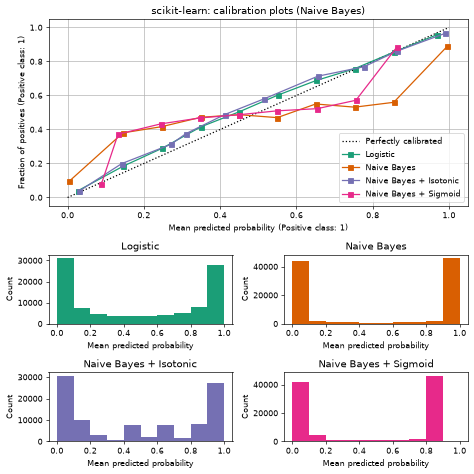

,Brier loss,Log loss,Roc auc,Precision,Recall,F1
Classifier,,,,,,
Logistic,0.099,0.323,0.937,0.872,0.851,0.862
Naive Bayes,0.118,0.783,0.940,0.857,0.876,0.867
Naive Bayes + Isotonic,0.098,0.371,0.939,0.883,0.836,0.859
Naive Bayes + Sigmoid,0.109,0.369,0.940,0.861,0.871,0.866


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from collections import defaultdict
import pandas as pd

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import brier_score_loss, f1_score, log_loss, precision_score, recall_score, roc_auc_score

X, y = make_classification(
    n_samples=100_000, n_features=20, n_informative=2, n_redundant=10, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.99, random_state=42)

lr = LogisticRegression(C=1.0)
gnb = GaussianNB()
gnb_isotonic = CalibratedClassifierCV(gnb, cv=2, method="isotonic")
gnb_sigmoid = CalibratedClassifierCV(gnb, cv=2, method="sigmoid")
clf_list = [
    (lr, "Logistic"),
    (gnb, "Naive Bayes"),
    (gnb_isotonic, "Naive Bayes + Isotonic"),
    (gnb_sigmoid, "Naive Bayes + Sigmoid"),
]

fig = plt.figure(figsize=(8, 8), dpi=60)
gs = GridSpec(4, 2)
colors = plt.get_cmap("Dark2")
ax_calibration_curve = fig.add_subplot(gs[:2, :2])
calibration_displays = {}
for i, (clf, name) in enumerate(clf_list):
    clf.fit(X_train, y_train)
    display = CalibrationDisplay.from_estimator(
        clf, X_test, y_test, n_bins=10, name=name, ax=ax_calibration_curve, color=colors(i)
    )
    calibration_displays[name] = display
ax_calibration_curve.grid()
ax_calibration_curve.set_title("scikit-learn: calibration plots (Naive Bayes)")
grid_positions = [(2, 0), (2, 1), (3, 0), (3, 1)]
for i, (_, name) in enumerate(clf_list):
    row, col = grid_positions[i]
    ax = fig.add_subplot(gs[row, col])
    ax.hist(calibration_displays[name].y_prob, range=(0, 1), bins=10, label=name, color=colors(i))
    ax.set(title=name, xlabel="Mean predicted probability", ylabel="Count")
plt.tight_layout()
plt.show()

scores = defaultdict(list)
sk = {}
for i, (clf, name) in enumerate(clf_list):
    clf.fit(X_train, y_train)
    y_prob = clf.predict_proba(X_test)
    y_pred = clf.predict(X_test)
    sk[name] = (y_prob, y_pred)
    scores["Classifier"].append(name)
    for metric in [brier_score_loss, log_loss, roc_auc_score]:
        score_name = metric.__name__.replace("_", " ").replace("score", "").capitalize()
        scores[score_name].append(metric(y_test, y_prob[:, 1]))
    for metric in [precision_score, recall_score, f1_score]:
        score_name = metric.__name__.replace("_", " ").replace("score", "").capitalize()
        scores[score_name].append(metric(y_test, y_pred))
score_df = pd.DataFrame(scores).set_index("Classifier")
display_df = score_df.round(decimals=3)
display_df

In [3]:
nb.share(X_train=X_train, y_train=y_train.astype(np.float64), X_test=X_test, y_test=y_test.astype(np.float64))
sk_curves = {name: calibration_curve(y_test, sk[name][0][:, 1], n_bins=10) for name in sk}
print("sklearn GaussianNB classes_:", gnb.classes_, "epsilon_:", gnb.epsilon_)

sklearn GaussianNB classes_: [0 1] epsilon_: 2.0543253195130414e-09


## 2. Moxie (native Mojo)

`GaussianNB` alone, then wrapped by `CalibratedClassifierCV` with `cv=2` for both methods. The adapter below is
the only glue: Moxie's calibration family accepts any `CalibrationEstimator`, and `GaussianNB` does not
conform to it directly (different `fit` signature for weights, no `response`/`class_labels`).

In [4]:
%%mojo calibration
import numojo as nm
from moxie.naive_bayes import GaussianNB, GaussianNBParams, NumericDomain
from moxie.calibration import CalibratedClassifierCV, CalibrationEstimator, CalibrationCV, calibration_curve
from moxie._calibration_algorithms import Array
from moxie.base import clone
from moxie_nb_io import load, save, save_floats

comptime GNB = GaussianNB[NumericDomain[DType.float64]]


struct GaussianNBCalibration(CalibrationEstimator):
    """Forward the calibration adapter contract to GaussianNB."""
    comptime Params = GaussianNBParams
    var model: GNB

    def __init__(out self, var priors: Optional[List[Float64]] = None, var_smoothing: Float64 = 1e-9) raises:
        self.model = GNB(priors=priors^, var_smoothing=var_smoothing)

    def get_params(self, deep: Bool = True) raises -> Self.Params:
        return self.model.get_params(deep)

    def set_params[origin: MutOrigin, params_origin: ImmOrigin](
        ref[origin] self, ref[params_origin] params: Self.Params
    ) raises -> ref[self] Self:
        _ = self.model.set_params(params)
        return self

    def __sklearn_clone__(self) raises -> Self:
        var params = self.model.get_params()
        return Self(priors=params.priors.copy(), var_smoothing=params.var_smoothing)

    def __sklearn_is_fitted__(self) -> Bool:
        return self.model.__sklearn_is_fitted__()

    def fit(mut self, X: Array, y: Array, sample_weight: Optional[Array] = None) raises:
        if sample_weight:
            var w = List[Float64]()
            for i in range(sample_weight.value().size):
                w.append(sample_weight.value().item(i))
            _ = self.model.fit(X, y, sample_weight=w^)
        else:
            _ = self.model.fit(X, y)

    def response(self, X: Array) raises -> Array:
        return self.model.predict_proba(X)

    def class_labels(self) raises -> Array:
        return self.model.classes_.copy()

    def uses_probabilities(self) -> Bool:
        return True


def column(p: Array, j: Int) raises -> Array:
    var out = nm.zeros[DType.float64](nm.Shape(p.shape[0]))
    for i in range(p.shape[0]):
        out[nm.Item(i)] = p.item(i, j)
    return out^


def emit(tag: String, y_test: Array, proba: Array, pred: Array) raises:
    save(tag + "_proba", proba)
    save(tag + "_pred", pred)
    var curve = calibration_curve(y_test, column(proba, 1), n_bins=10)
    save(tag + "_prob_true", curve[0])
    save(tag + "_prob_pred", curve[1])


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var X_test = load("X_test")
    var y_test = load("y_test")

    var gnb = GNB()
    _ = gnb.fit(X_train, y_train)
    save("theta", gnb.theta_)
    save("var", gnb.var_)
    save("class_prior", gnb.class_prior_)
    save("class_count", gnb.class_count_)
    save_floats("epsilon", List[Float64]([Float64(gnb.epsilon_)]))
    emit("gnb", y_test, gnb.predict_proba(X_test), gnb.predict(X_test))
    print("moxie GaussianNB classes_:", gnb.classes_, "epsilon_:", gnb.epsilon_)

    for method in [String("isotonic"), String("sigmoid")]:
        var calibrated = CalibratedClassifierCV(GaussianNBCalibration(), method=method, cv=CalibrationCV(2))
        _ = calibrated.fit(X_train, y_train)
        emit(method, y_test, calibrated.predict_proba(X_test), calibrated.predict(X_test))
        # clone gives an unfitted copy with the same configuration; refit reproduces the probabilities.
        var again = clone(calibrated)
        _ = again.fit(X_train, y_train)
        save(method + "_refit_proba", again.predict_proba(X_test))
        print(method, "calibrated_classifiers_:", len(calibrated.calibrated_classifiers_))

moxie GaussianNB classes_: [0.0000 1.0000]
1D-array  Shape: (2)  Strides: (1)  DType: f64  order: C  own data: True epsilon_: 2.0543253195130414e-09
isotonic calibrated_classifiers_: 2
sigmoid calibrated_classifiers_: 2


## 3. Side by side and parity

,Brier loss,Log loss,Roc auc,Precision,Recall,F1
Classifier,,,,,,
Naive Bayes,0.1176,0.7828,0.9404,0.8574,0.8759,0.8666
Naive Bayes + Isotonic,0.0983,0.3707,0.9386,0.8831,0.8362,0.8590
Naive Bayes + Sigmoid,0.1089,0.3689,0.9402,0.8611,0.8713,0.8662
,Brier loss,Log loss,Roc auc,Precision,Recall,F1
Classifier,,,,,,
Naive Bayes,0.1176,0.7828,0.9404,0.8574,0.8759,0.8666
Naive Bayes + Isotonic,0.0983,0.3707,0.9386,0.8831,0.8362,0.8590
Naive Bayes + Sigmoid,0.1089,0.3689,0.9402,0.8611,0.8713,0.8662


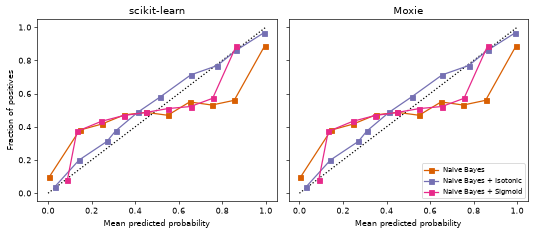

In [5]:
mx = nb.results["calibration"]
tags = {"Naive Bayes": "gnb", "Naive Bayes + Isotonic": "isotonic", "Naive Bayes + Sigmoid": "sigmoid"}
mx_scores = defaultdict(list)
for name, tag in tags.items():
    prob, pred = mx[f"{tag}_proba"], mx[f"{tag}_pred"]
    mx_scores["Classifier"].append(name)
    for metric in [brier_score_loss, log_loss, roc_auc_score]:
        mx_scores[metric.__name__.replace("_", " ").replace("score", "").capitalize()].append(metric(y_test, prob[:, 1]))
    for metric in [precision_score, recall_score, f1_score]:
        mx_scores[metric.__name__.replace("_", " ").replace("score", "").capitalize()].append(metric(y_test, pred))
mx_df = pd.DataFrame(mx_scores).set_index("Classifier")
moxie_nb.side_by_side(sklearn=score_df.loc[list(tags)].round(4), moxie=mx_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), dpi=60, sharey=True)
for ax, (title, curves) in zip(axes, [("scikit-learn", {n: sk_curves[n] for n in tags}),
                                       ("Moxie", {n: (mx[f"{t}_prob_true"], mx[f"{t}_prob_pred"]) for n, t in tags.items()})]):
    ax.plot([0, 1], [0, 1], "k:")
    for i, (name, (pt, pp)) in enumerate(curves.items()):
        ax.plot(pp, pt, "s-", color=colors(i + 1), label=name)
    ax.set(title=title, xlabel="Mean predicted probability")
axes[0].set_ylabel("Fraction of positives")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
nb.compare("GaussianNB theta_", gnb.theta_, mx["theta"], rtol=1e-12, atol=1e-14,
           reason="two-pass per-class mean vs NumPy pairwise summation over ~500 rows per class: rounding only")
nb.compare("GaussianNB var_", gnb.var_, mx["var"], rtol=1e-12, atol=1e-14,
           reason="two-pass centered variance vs NumPy's pairwise reductions: rounding only")
nb.compare("GaussianNB class_prior_", gnb.class_prior_, mx["class_prior"], exact=True)
nb.compare("GaussianNB class_count_", gnb.class_count_, mx["class_count"], exact=True)
nb.compare("GaussianNB epsilon_", np.array([gnb.epsilon_]), mx["epsilon"], rtol=1e-12,
           reason="var_smoothing * max column variance; reduction rounding")
nb.compare("GaussianNB predict", sk["Naive Bayes"][1].astype(float), mx["gnb_pred"], exact=True)
nb.compare("GaussianNB predict_proba", sk["Naive Bayes"][0], mx["gnb_proba"], rtol=0, atol=1e-9,
           reason="joint log-likelihoods of |~1e2| agree to ~1e-13 relative; exp of the difference "
                  "amplifies that into ~1e-11 absolute probability differences near the decision boundary")
for name in ["Naive Bayes + Isotonic", "Naive Bayes + Sigmoid"]:
    tag = tags[name]
    nb.compare(f"{name} predict", sk[name][1].astype(float), mx[f"{tag}_pred"], exact=True)
    nb.compare(f"{name} predict_proba", sk[name][0], mx[f"{tag}_proba"], rtol=0, atol=1e-8,
               reason="isotonic: piecewise-linear interpolation of the same GaussianNB probabilities; sigmoid: "
                      "Platt scaling fitted by an iterative optimizer (L-BFGS, tolerance-bounded) on each fold")
    nb.compare(f"{name} clone + refit predict_proba", mx[f"{tag}_proba"], mx[f"{tag}_refit_proba"], exact=True)
for name, tag in tags.items():
    nb.compare(f"{name} calibration_curve prob_true", sk_curves[name][0], mx[f"{tag}_prob_true"], rtol=1e-9, atol=1e-9,
               reason="bin fractions; equal unless a probability sits on a bin edge")
    nb.compare(f"{name} calibration_curve prob_pred", sk_curves[name][1], mx[f"{tag}_prob_pred"], rtol=1e-8, atol=1e-8,
               reason="bin means of probabilities that themselves carry the tolerances above")
nb.compare("score table (Brier, log loss, ROC AUC, precision, recall, F1)", score_df.loc[list(tags)].to_numpy(),
           mx_df.to_numpy(), rtol=1e-6, atol=1e-7, reason="metrics of the probabilities compared above")
nb.note("CalibratedClassifierCV(GaussianNB())", "GAP",
        "GaussianNB does not conform to moxie.calibration.CalibrationEstimator; the notebook writes a 40-line "
        "forwarding adapter. Owners: naive_bayes/calibration (ship adapters or a generic probability bridge).")
nb.note("LogisticRegression", "GAP", "moxie.linear_model has no LogisticRegression (linear_model family).")
nb.note("NaivelyCalibratedLinearSVC section", "GAP", "moxie has no LinearSVC; second half of the example not reproduced.")
nb.note("score metrics", "ADAPTED", "Brier/log-loss/ROC-AUC/precision/recall/F1 computed in Python from Moxie outputs; "
        "Moxie has no metrics module.")
nb.note("CalibrationDisplay", "ADAPTED", "Moxie points from moxie.calibration.calibration_curve, plotted with Matplotlib.")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
GaussianNB theta_,PASS,"(2, 20)","(2, 20)",0,0,"rtol=1e-12, atol=1e-14",,two-pass per-class mean vs NumPy pairwise summation over ~500 rows per class: rounding only
GaussianNB var_,PASS,"(2, 20)","(2, 20)",0,0,"rtol=1e-12, atol=1e-14",,two-pass centered variance vs NumPy's pairwise reductions: rounding only
GaussianNB class_prior_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
GaussianNB class_count_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
GaussianNB epsilon_,PASS,"(1,)","(1,)",0,0,"rtol=1e-12, atol=0",,var_smoothing * max column variance; reduction rounding
GaussianNB predict,PASS,"(99000,)","(99000,)",,,exact,0 mismatches,
GaussianNB predict_proba,PASS,"(99000, 2)","(99000, 2)",1.42e-14,5.67e-14,"rtol=0, atol=1e-09",,joint log-likelihoods of |~1e2| agree to ~1e-13 relative; exp of the difference amplifies that into ~1e-11 absolute probability differences near the decision boundary
Naive Bayes + Isotonic predict,PASS,"(99000,)","(99000,)",,,exact,0 mismatches,
Naive Bayes + Isotonic predict_proba,PASS,"(99000, 2)","(99000, 2)",2.11e-09,1.46e-07,"rtol=0, atol=1e-08",,"isotonic: piecewise-linear interpolation of the same GaussianNB probabilities; sigmoid: Platt scaling fitted by an iterative optimizer (L-BFGS, tolerance-bounded) on each fold"
Naive Bayes + Isotonic clone + refit predict_proba,PASS,"(99000, 2)","(99000, 2)",,,exact,0 mismatches,
